# Introduction to qim3d

**qim3d** is a Python library for **Quantitative Imaging in 3D**, developed at the [QIM Center](https://qim.dk) at DTU. It gives you generators for synthetic data, interactive visualization, filtering, segmentation and quantitative analysis, all working directly on plain NumPy arrays.

This notebook is a guided tour built around one idea: **synthetic data comes with ground truth**, so we can build a realistic problem, solve it, and *measure* how well we did.

What we will do:

1. generate a synthetic volume and look at it in several ways,
2. meet the other generators (cylinders, tubes, ropes, berries),
3. build a dataset of many objects together with its ground-truth labels,
4. degrade it with noise, then filter, threshold and label it,
5. **score** the result against the ground truth.

qim3d is installed with `pip install qim3d`. The two notebooks that follow use it for **local thickness** and the **structure tensor**.

In [1]:
import numpy as np
import qim3d

SEED = 42   # random seed, so every run gives the same data

## A first volume

`qim3d.generate.volume` creates a smooth, blob-like object from noise. The `noise_scale` controls how wiggly the shape is.

In [2]:
blob = qim3d.generate.volume(
    base_shape=(128, 128, 128),
    noise_scale=0.03,
    seed=SEED,
)

print(f"Shape: {blob.shape}")
print(f"Dtype: {blob.dtype}")
print(f"Intensity range: {blob.min()} .. {blob.max()}")

Shape: (128, 128, 128)
Dtype: uint8
Intensity range: 0 .. 255


### Looking at the volume in different ways

No single view tells the whole story, so qim3d offers several. Start with a **montage of slices**:

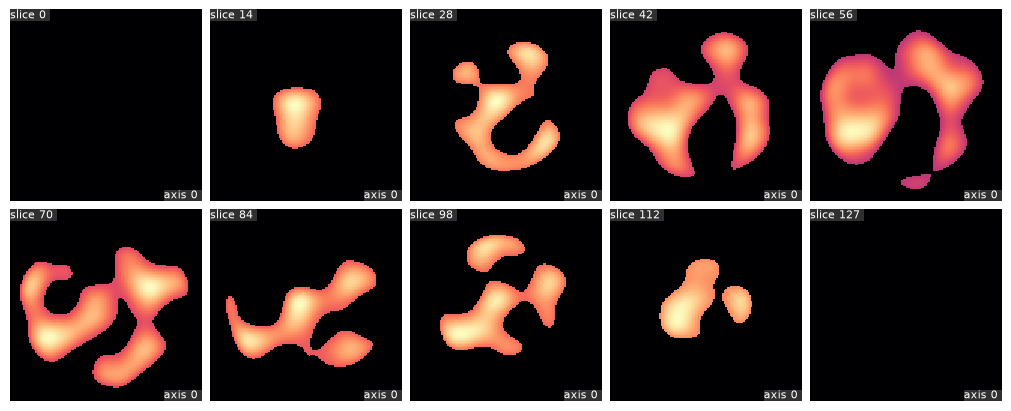

In [3]:
qim3d.viz.slices_grid(blob, n_slices=10)

The **intensity histogram** (zero-valued background voxels are ignored by default):

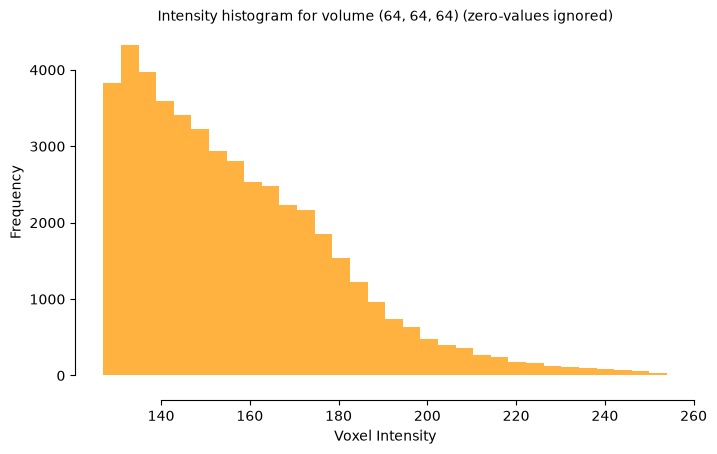

In [4]:
qim3d.viz.histogram(blob, bins=32, coarseness=2);

A hardware-accelerated **3D ray-cast rendering**. Rotate with the mouse:

In [ ]:
qim3d.viz.volumetric(blob)

A **turntable animation**, handy for slides and reports (this takes a few seconds to render; the GIF is also saved as `blob.gif` next to the notebook):

In [ ]:
qim3d.viz.export_rotation('blob.gif', blob, n_frames=64, fps=12, show=True)

### Beyond blobs

`generate.volume` can also produce cylinders and tubes, and qim3d has dedicated generators for structured objects: `generate.rope` (a twisted fibre bundle, which we will use in the structure tensor notebook) and `generate.berry` (a raspberry-like cluster of small spheres). Here is the central slice of each:

In [ ]:
shape3 = (96, 96, 96)
# a lower threshold lets the shape of cylinders and tubes dominate over the noise texture
tube_kw = dict(base_shape=(100, 64, 64), noise_scale=0.03, threshold=0.6, decay_rate=20, gamma=0.15, seed=SEED)

# (title, volume, axis along which to take the central slice)
gallery = [
    ("blob",            qim3d.generate.volume(base_shape=shape3, noise_scale=0.03, seed=SEED),             0),
    ("hollow blob",     qim3d.generate.volume(base_shape=shape3, noise_scale=0.03, hollow=4, seed=SEED),   0),
    ("cylinder (side)", qim3d.generate.volume(shape='cylinder', **tube_kw),                                1),
    ("tube (side)",     qim3d.generate.volume(shape='tube', tube_hole_ratio=0.4, **tube_kw),               1),
    ("rope (end-on)",   qim3d.generate.rope(shape=(96, 80, 80), seed=SEED),                                0),
    ("berry",           qim3d.generate.berry(shape=(128, 128, 128), seed=SEED),                            0),
]

To show all six together, we take each central slice, centre it on a 128 × 128 canvas and stack the canvases into one small volume, which `slices_grid` can then display as a montage.

In [ ]:
def central_slice(volume, axis, size=128):
    s = np.take(volume, volume.shape[axis] // 2, axis=axis)
    canvas = np.zeros((size, size), dtype=s.dtype)
    y0, x0 = (size - s.shape[0]) // 2, (size - s.shape[1]) // 2
    canvas[y0 : y0 + s.shape[0], x0 : x0 + s.shape[1]] = s
    return canvas

montage = np.stack([central_slice(vol, axis) for _, vol, axis in gallery])

print("Left to right, top to bottom: " + ", ".join(title for title, _, _ in gallery))
qim3d.viz.slices_grid(montage, slice_positions=list(range(len(gallery))), max_columns=3, image_size=3, display_positions=False)

## Generating a synthetic dataset

`qim3d.generate.volume_collection` places many non-overlapping, randomly rotated objects inside a larger container volume and also returns a **label volume** in which every object has its own integer ID. That is exactly what you need for developing and benchmarking instance segmentation, detection or measurement methods.

We ask for 24 objects with edge lengths between 24 and 64 voxels, so the dataset contains both small and large objects.

In [ ]:
collection, labels = qim3d.generate.volume_collection(
    n_volumes=24,
    collection_shape=(200, 200, 200),
    shape_range=((24, 24, 24), (64, 64, 64)),
    noise_range=(0.02, 0.04),
    seed=SEED,
)

print(f"Collection: shape {collection.shape}, dtype {collection.dtype}")
print(f"Labels:     {labels.max()} objects (IDs 1..{labels.max()}, 0 = background)")
print(f"Objects occupy {100 * (labels > 0).mean():.1f}% of the volume")

In [ ]:
qim3d.viz.slices_grid(collection, n_slices=10)

In [ ]:
qim3d.viz.volumetric(collection)

### Checking the labels

Here the labels come straight from the generator, but they could just as well be the output of a segmentation algorithm. `qim3d.viz.colormaps.segmentation` makes a colormap with distinct colours per label:

In [ ]:
cmap = qim3d.viz.colormaps.segmentation(n_labels=labels.max())
qim3d.viz.slices_grid(labels, colormap=cmap, max_value=labels.max(), n_slices=10)

`qim3d.viz.overlay` blends the labels over the image, with an adjustable transparency. Use the sliders to check that the labels sit where the objects are:

In [ ]:
qim3d.viz.overlay(collection, labels, colormaps=["gray", cmap], volume2_values=(0, labels.max()))

## From a noisy scan to a segmentation

Real scans are never this clean. Let's degrade the data and see how well we can recover the objects, using the ground truth to **score** the result.

`qim3d.generate.background` adds synthetic background noise to an existing volume. Here every voxel gets uniform random noise between 0 and 100 added to it (the result is clipped to the `uint8` range).

In [ ]:
noisy = qim3d.generate.background(
    background_shape=collection.shape,
    min_noise_value=0,
    max_noise_value=100,
    generate_method='add',
    apply_method='add',
    apply_to=collection,
    seed=SEED,
)

`qim3d.viz.overlay` is also a quick way to compare two volumes, here the clean and the noisy one:

In [ ]:
qim3d.viz.overlay(collection, noisy)

### Filtering and thresholding

Our plan has three steps:

1. **Median filter**: removes the strongest noise outliers while keeping edges sharp.
2. **Gaussian filter**: smooths the remaining, finer noise.
3. **Threshold** (Otsu's method picks the value separating background from objects automatically).

Each step has a parameter (`size`, `sigma`) that you can tune.

In [ ]:
median = qim3d.filters.median(noisy, size=4)
qim3d.viz.overlay(collection, median)

In [ ]:
smoothed = qim3d.filters.gaussian(median, sigma=2)
qim3d.viz.overlay(collection, smoothed)

In [ ]:
thr = qim3d.operations.threshold(smoothed, method='otsu')
print(f"Otsu threshold: {thr}")

binary = smoothed > thr

Compare the segmentation with the clean data:

In [ ]:
qim3d.viz.overlay(collection, binary, colormaps=["viridis", "gray"])

## Counting and measuring objects

`qim3d.segmentation.connected_components` labels every group of touching foreground voxels. The returned object holds the label volume (`cc.labels`) and the size of every component (`cc.sizes`, where index 0 is the background).

In [ ]:
cc = qim3d.segmentation.connected_components(binary)

sizes = cc.sizes[1:]   # drop the background entry, as we only want to count objects
print(f"{len(sizes)} connected components found; the ground truth has {labels.max()} objects")

## Scoring against the ground truth

Finding 24 objects is encouraging, but it does not tell us whether the objects are the right *shape*. Because we have the true labels, we can measure it. Everything here is plain NumPy.

**Voxel-wise agreement.** The *Dice score* is 1 for a perfect segmentation and 0 for none. The *IoU* (intersection over union) is a stricter version of the same idea.

In [ ]:
def dice_iou(prediction, truth):
    inter = np.logical_and(prediction, truth).sum()
    dice = 2 * inter / (prediction.sum() + truth.sum())
    iou = inter / np.logical_or(prediction, truth).sum()
    return dice, iou

truth = labels > 0
dice, iou = dice_iou(binary, truth)
print(f"Dice = {dice:.3f}, IoU = {iou:.3f}")

**Did the filtering matter?** Let's skip the filtering and threshold the noisy volume directly:

In [ ]:
binary_raw = noisy > qim3d.operations.threshold(noisy, method='otsu')
dice_raw, _ = dice_iou(binary_raw, truth)
n_raw = len(qim3d.segmentation.connected_components(binary_raw))

print(f"Without filtering: Dice = {dice_raw:.3f}, {n_raw} connected components")
print(f"With filtering:    Dice = {dice:.3f}, {len(cc)} connected components")

Without filtering, the noise breaks the objects into an enormous number of small fragments.

**Object by object.** For every true object we find the connected component that covers most of it, and compare the sizes:

In [ ]:
true_sizes = np.bincount(labels.ravel())[1:]
ratios, matched = [], []

for obj in range(1, labels.max() + 1):
    ids = cc.labels[labels == obj]
    ids = ids[ids > 0]
    best = np.bincount(ids).argmax()          # the component that overlaps this object the most
    matched.append(best)
    ratios.append(cc.sizes[best] / true_sizes[obj - 1])

ratios = np.array(ratios)
print(f"Every object matched to its own component: {len(set(matched)) == len(matched)}")
print(f"Measured size / true size: mean {ratios.mean():.2f}, range {ratios.min():.2f} - {ratios.max():.2f}")

The objects are found one-to-one, but they come out smaller than the labels. The dim parts of each object are lost to the threshold.

**Is Otsu's threshold the best choice?** With ground truth we can simply try a few values:

In [ ]:
print(f"{'threshold':>9s} {'Dice':>6s} {'components':>11s}")
for t in [70, 90, thr, 125]:
    b = smoothed > t
    d, _ = dice_iou(b, truth)
    print(f"{t:9.0f} {d:6.3f} {len(qim3d.segmentation.connected_components(b)):11d}")

A lower threshold scores better voxel-wise, but starts to produce extra, spurious components. Which one is "best" depends on what you want to measure, and without ground truth you could not even see this trade-off. This is the reason to benchmark on synthetic data.

## Where next?

- **Local thickness**: how thick is a structure at every point?
- **Structure tensor**: in which direction do fibres run, and how to visualize them in 3D?